# Experiment 5: DiagScale transfer and retention

Evaluate the three DiagScale rates against their own original checkpoints using five outer folds on excluded credit tables and the fixed non-credit panel. All rates are reported. Original and adapter inference share precision settings. Earlier full-parameter CPT used other precision, episode and sampling settings and is not treated as a one-factor control here.

Can restricting cross-table credit adaptation to query scaling preserve useful in-context behavior? This is fixed-endpoint domain CPT, not target-table validation-selected fine-tuning.


## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
from src.visualize import adapter_study as ds, publication as pub, comparisons as cmp, dashboards as db
sink = FigureSaver('experiment5/02_results')
report = cp.NotebookReport('Experiment 5: DiagScale transfer and retention', sink=sink)
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Can restricting cross-table credit adaptation to query scaling preserve useful in-context behavior? This is fixed-endpoint domain CPT, not target-table validation-selected fine-tuning.')
runs = [cp.load_campaign(5, track) for track in ('pd', 'lgd')]
from src.visualize import prediction_diagnostics as pred


DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


## 1. Checkpoint and benchmark coverage

In [2]:
for run in runs:
    report.table(run.track.upper()+' evidence', pub.availability(run))
    report.table(run.track.upper()+' paired benchmark coverage', cmp.benchmark_coverage(run))
report.add('1. Checkpoint and benchmark coverage', 'Trained and original cells need all five finite outer folds. Non-credit table comparisons additionally require all four training-dataset partitions. Missing cells remain unavailable.')

,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,24,DATA manifests
2,Epoch rows,18888,Project training diagnostics
3,Milestone rows,144,Project trajectory diagnostics
4,Benchmark folds,1815,Project final evaluation


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,12,12,51,17
1,credit,TabPFN v3,12,12,51,17
2,ood,TabICLv2,12,12,48,4
3,ood,TabPFN v3,12,12,48,4


,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,24,DATA manifests
2,Epoch rows,40032,Project training diagnostics
3,Milestone rows,144,Project trajectory diagnostics
4,Benchmark folds,1320,Project final evaluation


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,12,12,24,8
1,credit,TabPFN v3,12,12,24,8
2,ood,TabICLv2,12,12,48,4
3,ood,TabPFN v3,12,12,48,4


## 2. Five-fold credit transfer and non-credit retention

Points show tables; diamonds show their mean and intervals their interquartile range. All three rates share a table cohort within each model/domain panel. PD uses AUC and LGD uses R².

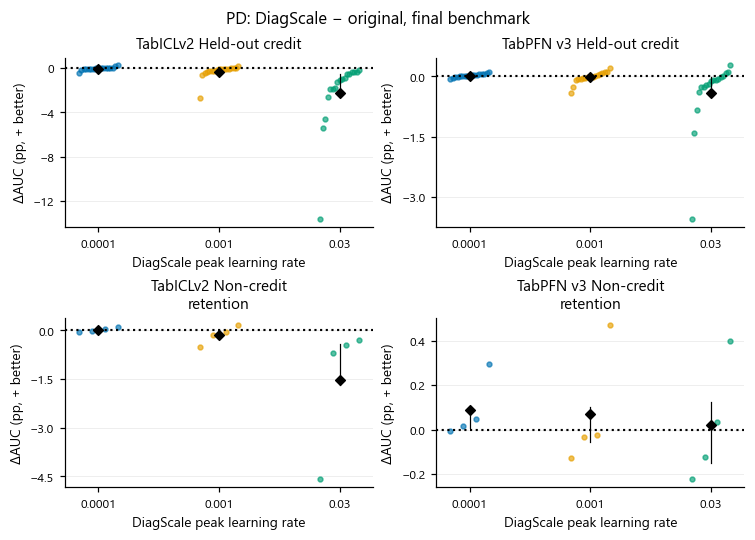

Experiment 5, final five-fold benchmark: paired change in AUC (ΔAUC (pp, + better)) of DiagScale CPT, which learns only multiplicative attention query scales, relative to the original checkpoint of the same base, at each of the three adapter learning rates. Upper panels: held-out credit tables; lower panels: the four same-task non-credit retention tables (each first averaged over all four CPT partitions). Points are tables, diamonds equal-table means and vertical bars the table interquartile range (heterogeneity, not confidence intervals). Only tables measured at all three rates enter a panel, and every adapted/original pair has five finite outer folds. Original and adapted TabICLv2 both use FP32 inference without FA3. Positive values favour DiagScale. The summary table reports plotted values in display units (column display_scale); paired table values are in native units.

,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,Bondora Peer-to-Peer,credit,roc_auc,-9.732975e-04,0.897219,0.896246,1
1,TabICLv2,0.0001,0.0,False,one_sample,Cobranded,credit,roc_auc,-3.996291e-04,0.842712,0.842313,1
2,TabICLv2,0.0001,0.0,False,one_sample,Credit Risk,credit,roc_auc,-1.094880e-04,0.955257,0.955147,1
3,TabICLv2,0.0001,0.0,False,one_sample,GMSC,credit,roc_auc,-1.724778e-04,0.867210,0.867037,1
4,TabICLv2,0.0001,0.0,False,one_sample,German Credit,credit,roc_auc,1.857314e-03,0.790140,0.791998,1
...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,0.0300,0.0,False,one_sample,PropPD2,credit,roc_auc,-1.881657e-03,0.657340,0.655459,1
98,TabPFN v3,0.0300,0.0,False,one_sample,SBA Loans Case,credit,roc_auc,7.976240e-07,0.989833,0.989834,1
99,TabPFN v3,0.0300,0.0,False,one_sample,Taiwan Credit Card,credit,roc_auc,-7.870495e-04,0.789665,0.788878,1
100,TabPFN v3,0.0300,0.0,False,one_sample,Thomas,credit,roc_auc,2.787694e-03,0.651588,0.654375,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,openml_46905,ood,roc_auc,0.000467,0.845801,0.846268,4
1,TabICLv2,0.0001,0.0,False,one_sample,openml_46947,ood,roc_auc,-0.000478,0.936670,0.936192,4
2,TabICLv2,0.0001,0.0,False,one_sample,openml_46952,ood,roc_auc,-0.000300,0.940093,0.939792,4
3,TabICLv2,0.0001,0.0,False,one_sample,openml_46956,ood,roc_auc,0.001037,0.776168,0.777205,4
4,TabICLv2,0.0010,0.0,False,one_sample,openml_46905,ood,roc_auc,-0.005154,0.845801,0.840646,4
5,TabICLv2,0.0010,0.0,False,one_sample,openml_46947,ood,roc_auc,-0.001492,0.936670,0.935179,4
6,TabICLv2,0.0010,0.0,False,one_sample,openml_46952,ood,roc_auc,-0.000466,0.940093,0.939627,4
7,TabICLv2,0.0010,0.0,False,one_sample,openml_46956,ood,roc_auc,0.001529,0.776168,0.777697,4
8,TabICLv2,0.0300,0.0,False,one_sample,openml_46905,ood,roc_auc,-0.045998,0.845801,0.799803,4
9,TabICLv2,0.0300,0.0,False,one_sample,openml_46947,ood,roc_auc,-0.007074,0.936670,0.929596,4


,domain,method_name,test_dataset_id,split,mean,folds,metric
0,credit,catboost,Bondora Peer-to-Peer,0,0.891854,5,roc_auc
1,credit,catboost,Cobranded,3,0.841930,5,roc_auc
2,credit,catboost,Credit Risk,2,0.947004,5,roc_auc
3,credit,catboost,GMSC,1,0.866146,5,roc_auc
4,credit,catboost,German Credit,1,0.763857,5,roc_auc
...,...,...,...,...,...,...,...
358,noncredit,xgboost,openml_46952,3,0.926484,5,roc_auc
359,noncredit,xgboost,openml_46956,0,0.759358,5,roc_auc
360,noncredit,xgboost,openml_46956,1,0.759358,5,roc_auc
361,noncredit,xgboost,openml_46956,2,0.759358,5,roc_auc


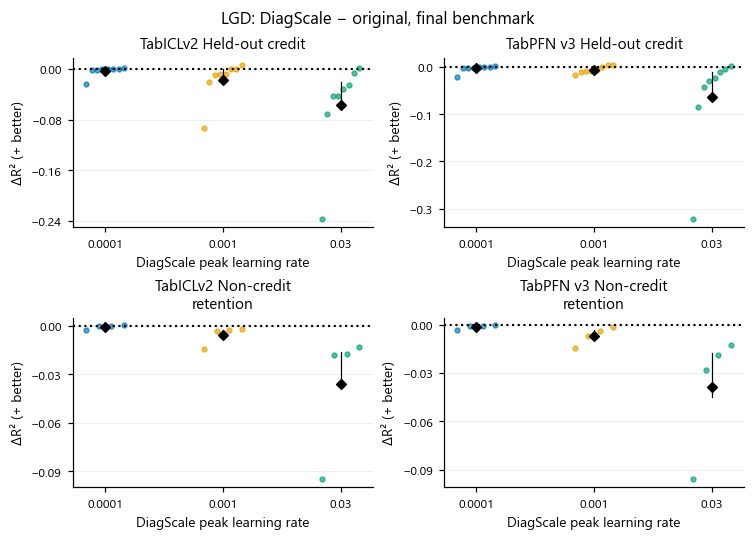

Experiment 5, final five-fold benchmark: paired change in R² (ΔR² (+ better)) of DiagScale CPT, which learns only multiplicative attention query scales, relative to the original checkpoint of the same base, at each of the three adapter learning rates. Upper panels: held-out credit tables; lower panels: the four same-task non-credit retention tables (each first averaged over all four CPT partitions). Points are tables, diamonds equal-table means and vertical bars the table interquartile range (heterogeneity, not confidence intervals). Only tables measured at all three rates enter a panel, and every adapted/original pair has five finite outer folds. Original and adapted TabICLv2 both use FP32 inference without FA3. Positive values favour DiagScale. The summary table reports plotted values in display units (column display_scale); paired table values are in native units.

,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,Freddie Mac,credit,r2,-0.000011,0.383912,0.383901,1
1,TabICLv2,0.0001,0.0,False,one_sample,LendingClub (LGD),credit,r2,0.000029,0.763625,0.763654,1
2,TabICLv2,0.0001,0.0,False,one_sample,PropLGD1,credit,r2,-0.022995,0.642400,0.619405,1
3,TabICLv2,0.0001,0.0,False,one_sample,PropLGD2,credit,r2,-0.000249,0.727264,0.727015,1
4,TabICLv2,0.0001,0.0,False,one_sample,PropLGD3,credit,r2,-0.000234,0.212188,0.211954,1
5,TabICLv2,0.0001,0.0,False,one_sample,PropLGD4,credit,r2,0.001281,0.417995,0.419276,1
6,TabICLv2,0.0001,0.0,False,one_sample,PropLGD5,credit,r2,-0.001635,0.373869,0.372234,1
7,TabICLv2,0.0001,0.0,False,one_sample,SBA Loans Case (LGD),credit,r2,-0.000877,0.734035,0.733157,1
8,TabICLv2,0.0010,0.0,False,one_sample,Freddie Mac,credit,r2,-0.020475,0.383912,0.363437,1
9,TabICLv2,0.0010,0.0,False,one_sample,LendingClub (LGD),credit,r2,-0.000748,0.763625,0.762877,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,openml_46904,ood,r2,-0.000172,0.974136,0.973964,4
1,TabICLv2,0.0001,0.0,False,one_sample,openml_46917,ood,r2,0.000328,0.947698,0.948025,4
2,TabICLv2,0.0001,0.0,False,one_sample,openml_46949,ood,r2,-0.002759,0.765400,0.762641,4
3,TabICLv2,0.0001,0.0,False,one_sample,openml_46961,ood,r2,-0.000048,0.931251,0.931203,4
4,TabICLv2,0.0010,0.0,False,one_sample,openml_46904,ood,r2,-0.002906,0.974136,0.971231,4
5,TabICLv2,0.0010,0.0,False,one_sample,openml_46917,ood,r2,-0.002754,0.947698,0.944944,4
6,TabICLv2,0.0010,0.0,False,one_sample,openml_46949,ood,r2,-0.014267,0.765400,0.751133,4
7,TabICLv2,0.0010,0.0,False,one_sample,openml_46961,ood,r2,-0.002044,0.931251,0.929207,4
8,TabICLv2,0.0300,0.0,False,one_sample,openml_46904,ood,r2,-0.017260,0.974136,0.956876,4
9,TabICLv2,0.0300,0.0,False,one_sample,openml_46917,ood,r2,-0.012935,0.947698,0.934763,4


,domain,method_name,test_dataset_id,split,mean,folds,metric
0,credit,catboost,Freddie Mac,1,0.378061,5,r2
1,credit,catboost,LendingClub (LGD),2,0.760880,5,r2
2,credit,catboost,PropLGD1,1,0.652285,5,r2
3,credit,catboost,PropLGD2,0,0.676403,5,r2
4,credit,catboost,PropLGD3,0,0.207786,5,r2
...,...,...,...,...,...,...,...
259,noncredit,xgboost,openml_46949,3,0.665845,5,r2
260,noncredit,xgboost,openml_46961,0,0.923687,5,r2
261,noncredit,xgboost,openml_46961,1,0.923687,5,r2
262,noncredit,xgboost,openml_46961,2,0.923687,5,r2


In [3]:
for run in runs:
    cp.show(sink, ds.plot_benchmark(run))
    for domain in ('credit', 'ood'):
        report.table(run.track.upper()+' '+domain+' paired primary scores', ds.benchmark_tables(run, domain=domain))
    report.table(run.track.upper()+' absolute scores including available classical controls', ds.absolute_scores(run))
report.add('2. Five-fold credit transfer and non-credit retention', 'Positive effects favor DiagScale. Table spread is not a confidence interval. The highest observed rate is not a validated selected recipe. Classical models provide benchmark context rather than a checkpoint-paired causal contrast.')

## 3. Probability quality and regression errors

Saved raw test predictions additionally measure systematic over/underprediction and paired prediction changes. These diagnostics describe observed errors; they do not identify theoretical bias or context variance.


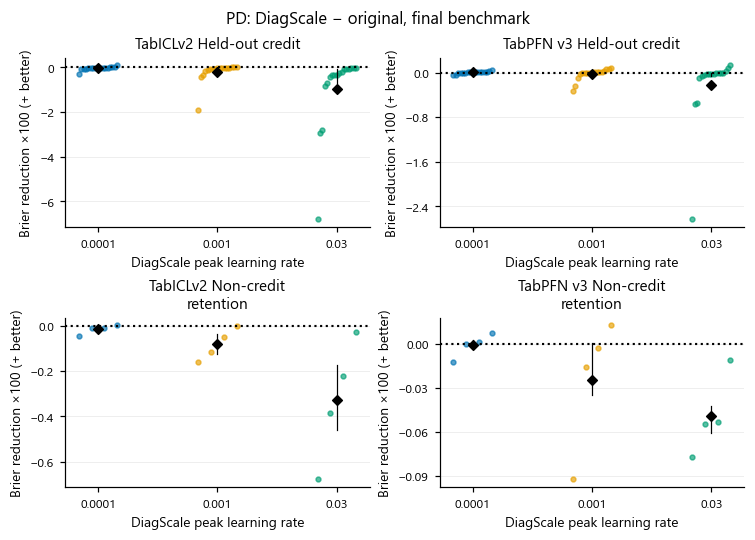

Experiment 5, final five-fold benchmark: paired change in Brier score (Brier reduction ×100 (+ better)) of DiagScale CPT, which learns only multiplicative attention query scales, relative to the original checkpoint of the same base, at each of the three adapter learning rates. Upper panels: held-out credit tables; lower panels: the four same-task non-credit retention tables (each first averaged over all four CPT partitions). Points are tables, diamonds equal-table means and vertical bars the table interquartile range (heterogeneity, not confidence intervals). Only tables measured at all three rates enter a panel, and every adapted/original pair has five finite outer folds. Original and adapted TabICLv2 both use FP32 inference without FA3. Positive values favour DiagScale. The summary table reports plotted values in display units (column display_scale); paired table values are in native units.

,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,Bondora Peer-to-Peer,credit,brier_score,-0.000326,0.080427,0.080753,1
1,TabICLv2,0.0001,0.0,False,one_sample,Cobranded,credit,brier_score,-0.000147,0.130724,0.130871,1
2,TabICLv2,0.0001,0.0,False,one_sample,Credit Risk,credit,brier_score,-0.000721,0.049369,0.050090,1
3,TabICLv2,0.0001,0.0,False,one_sample,GMSC,credit,brier_score,-0.000056,0.049082,0.049138,1
4,TabICLv2,0.0001,0.0,False,one_sample,German Credit,credit,brier_score,0.000277,0.162387,0.162110,1
...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,0.0300,0.0,False,one_sample,PropPD2,credit,brier_score,-0.000067,0.082364,0.082431,1
98,TabPFN v3,0.0300,0.0,False,one_sample,SBA Loans Case,credit,brier_score,0.000305,0.033251,0.032947,1
99,TabPFN v3,0.0300,0.0,False,one_sample,Taiwan Credit Card,credit,brier_score,-0.000021,0.133059,0.133081,1
100,TabPFN v3,0.0300,0.0,False,one_sample,Thomas,credit,brier_score,0.000786,0.183508,0.182722,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,openml_46905,ood,brier_score,-0.000128,0.040409,0.040537,4
1,TabICLv2,0.0001,0.0,False,one_sample,openml_46947,ood,brier_score,-0.000108,0.067741,0.067850,4
2,TabICLv2,0.0001,0.0,False,one_sample,openml_46952,ood,brier_score,-0.000461,0.085743,0.086204,4
3,TabICLv2,0.0001,0.0,False,one_sample,openml_46956,ood,brier_score,0.000010,0.056575,0.056565,4
4,TabICLv2,0.0010,0.0,False,one_sample,openml_46905,ood,brier_score,-0.001623,0.040409,0.042032,4
5,TabICLv2,0.0010,0.0,False,one_sample,openml_46947,ood,brier_score,-0.000513,0.067741,0.068255,4
6,TabICLv2,0.0010,0.0,False,one_sample,openml_46952,ood,brier_score,-0.001153,0.085743,0.086896,4
7,TabICLv2,0.0010,0.0,False,one_sample,openml_46956,ood,brier_score,0.000002,0.056575,0.056573,4
8,TabICLv2,0.0300,0.0,False,one_sample,openml_46905,ood,brier_score,-0.006788,0.040409,0.047198,4
9,TabICLv2,0.0300,0.0,False,one_sample,openml_46947,ood,brier_score,-0.002233,0.067741,0.069975,4


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,Bondora Peer-to-Peer,credit,log_loss,-0.001056,0.256125,0.257181,1
1,TabICLv2,0.0001,0.0,False,one_sample,Cobranded,credit,log_loss,-0.000355,0.404901,0.405256,1
2,TabICLv2,0.0001,0.0,False,one_sample,Credit Risk,credit,log_loss,-0.001687,0.176281,0.177967,1
3,TabICLv2,0.0001,0.0,False,one_sample,GMSC,credit,log_loss,-0.000296,0.178190,0.178486,1
4,TabICLv2,0.0001,0.0,False,one_sample,German Credit,credit,log_loss,0.001063,0.496485,0.495422,1
...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,0.0300,0.0,False,one_sample,PropPD2,credit,log_loss,-0.000737,0.297585,0.298322,1
98,TabPFN v3,0.0300,0.0,False,one_sample,SBA Loans Case,credit,log_loss,0.001574,0.119508,0.117934,1
99,TabPFN v3,0.0300,0.0,False,one_sample,Taiwan Credit Card,credit,log_loss,0.000072,0.424775,0.424703,1
100,TabPFN v3,0.0300,0.0,False,one_sample,Thomas,credit,log_loss,0.001154,0.550369,0.549215,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,openml_46905,ood,log_loss,0.000423,0.157558,0.157135,4
1,TabICLv2,0.0001,0.0,False,one_sample,openml_46947,ood,log_loss,-0.000724,0.218649,0.219373,4
2,TabICLv2,0.0001,0.0,False,one_sample,openml_46952,ood,log_loss,-0.000771,0.288323,0.289093,4
3,TabICLv2,0.0001,0.0,False,one_sample,openml_46956,ood,log_loss,0.000303,0.212404,0.212101,4
4,TabICLv2,0.0010,0.0,False,one_sample,openml_46905,ood,log_loss,-0.004092,0.157558,0.161651,4
5,TabICLv2,0.0010,0.0,False,one_sample,openml_46947,ood,log_loss,-0.002923,0.218649,0.221572,4
6,TabICLv2,0.0010,0.0,False,one_sample,openml_46952,ood,log_loss,-0.002212,0.288323,0.290535,4
7,TabICLv2,0.0010,0.0,False,one_sample,openml_46956,ood,log_loss,0.000556,0.212404,0.211848,4
8,TabICLv2,0.0300,0.0,False,one_sample,openml_46905,ood,log_loss,-0.024556,0.157558,0.182115,4
9,TabICLv2,0.0300,0.0,False,one_sample,openml_46947,ood,log_loss,-0.012009,0.218649,0.230658,4


...

,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,openml_46904,ood,rmse,-0.002829,1.105748,1.109213,4
1,TabICLv2,0.0001,0.0,False,one_sample,openml_46917,ood,rmse,0.003919,3.786589,3.773029,4
2,TabICLv2,0.0001,0.0,False,one_sample,openml_46949,ood,rmse,-0.005857,2.963379,2.980737,4
3,TabICLv2,0.0001,0.0,False,one_sample,openml_46961,ood,rmse,-0.000339,8.980406,8.983488,4
4,TabICLv2,0.0010,0.0,False,one_sample,openml_46904,ood,rmse,-0.052649,1.105748,1.164643,4
5,TabICLv2,0.0010,0.0,False,one_sample,openml_46917,ood,rmse,-0.025966,3.786589,3.883596,4
6,TabICLv2,0.0010,0.0,False,one_sample,openml_46949,ood,rmse,-0.029897,2.963379,3.051984,4
7,TabICLv2,0.0010,0.0,False,one_sample,openml_46961,ood,rmse,-0.014676,8.980406,9.112406,4
8,TabICLv2,0.0300,0.0,False,one_sample,openml_46904,ood,rmse,-0.285464,1.105748,1.422804,4
9,TabICLv2,0.0300,0.0,False,one_sample,openml_46917,ood,rmse,-0.123637,3.786589,4.234737,4


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,Freddie Mac,credit,mae,-0.000501,0.197255,0.197756,1
1,TabICLv2,0.0001,0.0,False,one_sample,LendingClub (LGD),credit,mae,0.000004,0.063667,0.063662,1
2,TabICLv2,0.0001,0.0,False,one_sample,PropLGD1,credit,mae,-0.008510,0.157501,0.166012,1
3,TabICLv2,0.0001,0.0,False,one_sample,PropLGD2,credit,mae,0.000020,0.098312,0.098292,1
4,TabICLv2,0.0001,0.0,False,one_sample,PropLGD3,credit,mae,-0.000278,0.219361,0.219639,1
5,TabICLv2,0.0001,0.0,False,one_sample,PropLGD4,credit,mae,0.001144,0.210988,0.209844,1
6,TabICLv2,0.0001,0.0,False,one_sample,PropLGD5,credit,mae,-0.001018,0.238580,0.239598,1
7,TabICLv2,0.0001,0.0,False,one_sample,SBA Loans Case (LGD),credit,mae,0.000014,0.080903,0.080889,1
8,TabICLv2,0.0010,0.0,False,one_sample,Freddie Mac,credit,mae,-0.004427,0.197255,0.201681,1
9,TabICLv2,0.0010,0.0,False,one_sample,LendingClub (LGD),credit,mae,0.000173,0.063667,0.063494,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.0001,0.0,False,one_sample,openml_46904,ood,mae,-0.006095,0.725305,0.731400,4
1,TabICLv2,0.0001,0.0,False,one_sample,openml_46917,ood,mae,0.013358,2.361429,2.348071,4
2,TabICLv2,0.0001,0.0,False,one_sample,openml_46949,ood,mae,-0.014026,1.747524,1.761550,4
3,TabICLv2,0.0001,0.0,False,one_sample,openml_46961,ood,mae,0.002986,4.848941,4.845954,4
4,TabICLv2,0.0010,0.0,False,one_sample,openml_46904,ood,mae,-0.029191,0.725305,0.754497,4
5,TabICLv2,0.0010,0.0,False,one_sample,openml_46917,ood,mae,-0.110812,2.361429,2.472241,4
6,TabICLv2,0.0010,0.0,False,one_sample,openml_46949,ood,mae,-0.088358,1.747524,1.835882,4
7,TabICLv2,0.0010,0.0,False,one_sample,openml_46961,ood,mae,-0.101185,4.848941,4.950126,4
8,TabICLv2,0.0300,0.0,False,one_sample,openml_46904,ood,mae,-0.195272,0.725305,0.920577,4
9,TabICLv2,0.0300,0.0,False,one_sample,openml_46917,ood,mae,-0.442512,2.361429,2.803941,4


,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,HMEQ,0,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,HMEQ,0,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
...,...,...,...,...,...,...
97,TabPFN v3,LendingClub,3,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
98,TabPFN v3,LendingClub,3,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
99,TabPFN v3,SBA Loans Case,3,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
100,TabPFN v3,SBA Loans Case,3,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.001,730176,0.138105,0.132381,0.128757,-0.005724,-0.009348,-0.003624,0.080427,0.081434,-0.001007,-0.003624,0.024850,0.012471
1,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.0001,730176,0.138105,0.132381,0.131080,-0.005724,-0.007025,-0.001301,0.080427,0.080753,-0.000326,-0.001301,0.009335,0.004365
2,TabICLv2,Bondora Peer-to-Peer,0,Adapter LR 0.03,730176,0.138105,0.132381,0.116198,-0.005724,-0.021907,-0.016184,0.080427,0.084557,-0.004130,-0.016184,0.057971,0.031047
3,TabICLv2,HMEQ,0,Adapter LR 0.001,5960,0.199497,0.190217,0.188914,-0.009280,-0.010582,-0.001303,0.017732,0.022054,-0.004322,-0.001303,0.055424,0.016230
4,TabICLv2,HMEQ,0,Adapter LR 0.0001,5960,0.199497,0.190217,0.189762,-0.009280,-0.009735,-0.000455,0.017732,0.018392,-0.000660,-0.000455,0.016369,0.005008
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,LendingClub,3,Adapter LR 0.0001,9578,0.160054,0.140981,0.141481,-0.019073,-0.018573,0.000500,0.126388,0.126330,0.000058,0.000500,0.003244,0.002420
98,TabPFN v3,LendingClub,3,Adapter LR 0.03,9578,0.160054,0.140981,0.137704,-0.019073,-0.022350,-0.003277,0.126388,0.126565,-0.000177,-0.003277,0.012577,0.008254
99,TabPFN v3,SBA Loans Case,3,Adapter LR 0.001,2102,0.326356,0.326395,0.325685,0.000039,-0.000671,-0.000632,0.033249,0.032629,0.000620,-0.000710,0.017206,0.006324
100,TabPFN v3,SBA Loans Case,3,Adapter LR 0.0001,2102,0.326356,0.326395,0.325930,0.000039,-0.000426,-0.000387,0.033249,0.033034,0.000215,-0.000465,0.007526,0.003145


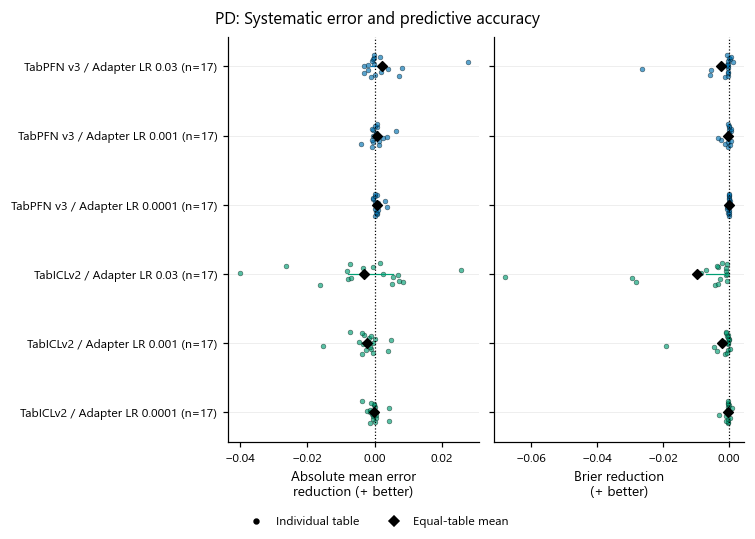

PD. Matched five-fold out-of-fold predictions on held-out credit tables. Circles show individual tables; their small vertical offsets follow table-name order and have no quantitative meaning. Black diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

,base,dataset,partition,arm,status,reason
0,TabICLv2,PropLGD2,0,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,PropLGD2,0,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,PropLGD2,0,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,PropLGD3,0,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,PropLGD3,0,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,PropLGD3,0,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,Freddie Mac,1,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,Freddie Mac,1,Adapter LR 0.0001,verified,"Five folds; matched row identities, targets an..."
8,TabICLv2,Freddie Mac,1,Adapter LR 0.03,verified,"Five folds; matched row identities, targets an..."
9,TabICLv2,PropLGD1,1,Adapter LR 0.001,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,PropLGD2,0,Adapter LR 0.001,4637,0.392032,0.389712,0.393427,-0.002320,0.001395,0.000926,0.020063,0.020652,-5.892551e-04,0.003715,0.026573,0.017765
1,TabICLv2,PropLGD2,0,Adapter LR 0.0001,4637,0.392032,0.389712,0.390301,-0.002320,-0.001731,0.000589,0.020063,0.020083,-1.969314e-05,0.000589,0.010491,0.007083
2,TabICLv2,PropLGD2,0,Adapter LR 0.03,4637,0.392032,0.389712,0.394144,-0.002320,0.002112,0.000209,0.020063,0.023214,-3.150729e-03,0.004432,0.053251,0.038674
3,TabICLv2,PropLGD3,0,Adapter LR 0.001,2545,0.228130,0.233124,0.233515,0.004994,0.005385,-0.000391,0.085241,0.085240,7.112293e-07,0.000391,0.013346,0.010592
4,TabICLv2,PropLGD3,0,Adapter LR 0.0001,2545,0.228130,0.233124,0.235842,0.004994,0.007712,-0.002718,0.085241,0.085259,-1.835225e-05,0.002718,0.005058,0.003272
5,TabICLv2,PropLGD3,0,Adapter LR 0.03,2545,0.228130,0.233124,0.233317,0.004994,0.005187,-0.000193,0.085241,0.085997,-7.562364e-04,0.000193,0.033316,0.025613
6,TabICLv2,Freddie Mac,1,Adapter LR 0.001,16002,0.458843,0.461581,0.463197,0.002739,0.004355,-0.001616,0.062385,0.064457,-2.072004e-03,0.001616,0.044497,0.033762
7,TabICLv2,Freddie Mac,1,Adapter LR 0.0001,16002,0.458843,0.461581,0.461508,0.002739,0.002665,0.000073,0.062385,0.062386,-1.140133e-06,-0.000073,0.022367,0.016792
8,TabICLv2,Freddie Mac,1,Adapter LR 0.03,16002,0.458843,0.461581,0.467596,0.002739,0.008754,-0.006015,0.062385,0.069586,-7.201181e-03,0.006015,0.084358,0.065447
9,TabICLv2,PropLGD1,1,Adapter LR 0.001,57932,0.704420,0.695587,0.716759,-0.008833,0.012339,-0.003505,0.062182,0.078380,-1.619795e-02,0.021172,0.115448,0.070154


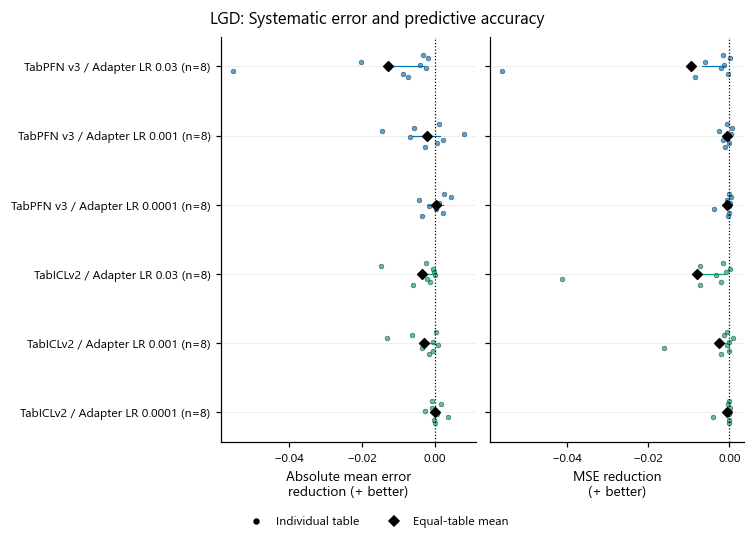

LGD. Matched five-fold out-of-fold predictions on held-out credit tables. Circles show individual tables; their small vertical offsets follow table-name order and have no quantitative meaning. Black diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

In [4]:
for run in runs:
    if run.track == 'pd':
        cp.show(sink, ds.plot_benchmark(run, metric='brier_score'))
    for metric in (('brier_score', 'log_loss', 'ece', 'f1') if run.track == 'pd' else ('rmse', 'mae')):
        for domain in ('credit', 'ood'):
            report.table(run.track.upper()+' '+domain+' '+metric, ds.benchmark_tables(run, metric, domain))
for run in runs:
    prediction_values, prediction_coverage = pred.analyze(run)
    report.table(run.track.upper()+' saved prediction coverage', prediction_coverage)
    report.table(run.track.upper()+' paired per-table prediction diagnostics', prediction_values)
    cp.show(sink, pred.plot_diagnostics(prediction_values, run.track, coverage=prediction_coverage), track=run.track)
report.add('3. Probability quality and regression errors', 'Probabilities are evaluated at test prevalence. F1/calibration rules use inner validation only. RMSE effects are fractional reductions relative to the matched original; other differences retain their metric scale. Unsupported/nonfinite metrics are not filled with zeros.' + '\n' + pred.NOTE)


## 4. Cost and interpretation boundaries

In [5]:
for run in runs:
    report.table(run.track.upper()+' training resources', ds.costs(run))
report.add('4. Cost and interpretation boundaries', 'This experiment tests a cross-table DiagScale recipe. It is not a literal reproduction of target-table adapter fine-tuning, nor a pure parameter-count ablation against previous full-update runs. Overlapping training corpora, related data sources and the small retention panel limit independence and generality claims. Report unfavorable outcomes alongside improvements.')

,trial_name,base,learning_rate,partition,status,optimizer_selected_params,total_params,rows_seen,elapsed_sec,gpu_hours,peak_gpu_gb,query_scale_delta_rms
0,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0001,0,OK,13056,53166200,70788725,6168.156499,1.713377,39.133,0.032038
1,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0010,0,OK,13056,53166200,70788725,6147.738720,1.707705,39.345,0.184803
2,cpt_diagscale_v1_s00_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0300,0,OK,13056,53166200,70788725,6169.156107,1.713654,39.133,1.263868
3,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0001,0,OK,7296,27559554,70788725,4766.576668,1.324049,15.873,0.038982
4,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0010,0,OK,7296,27559554,70788725,4770.898052,1.325249,15.873,0.275439
5,cpt_diagscale_v1_s00_pd_tabicl-classifier-v2-2...,TabICLv2,0.0300,0,OK,7296,27559554,70788725,4776.914145,1.326921,15.763,1.640877
6,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0001,1,OK,13056,53166200,69239144,6049.478816,1.680411,39.771,0.033577
7,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0010,1,OK,13056,53166200,69239144,6071.310221,1.686475,39.558,0.199136
8,cpt_diagscale_v1_s01_pd_tabpfn-v3-classifier-v...,TabPFN v3,0.0300,1,OK,13056,53166200,69239144,6096.050658,1.693347,39.771,1.233613
9,cpt_diagscale_v1_s01_pd_tabicl-classifier-v2-2...,TabICLv2,0.0001,1,OK,7296,27559554,69239144,4809.640543,1.336011,15.873,0.053894


,trial_name,base,learning_rate,partition,status,optimizer_selected_params,total_params,rows_seen,elapsed_sec,gpu_hours,peak_gpu_gb,query_scale_delta_rms
0,cpt_diagscale_v1_s00_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0001,0,OK,12672,58287616,40087565,3079.852087,0.855514,23.140,0.080004
1,cpt_diagscale_v1_s00_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0010,0,OK,12672,58287616,40087565,3075.246109,0.854235,23.140,0.373031
2,cpt_diagscale_v1_s00_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0300,0,OK,12672,58287616,40087565,3096.738649,0.860205,23.140,2.073015
3,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0001,0,OK,7296,28552287,40087565,2277.811915,0.632726,6.741,0.056318
4,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0010,0,OK,7296,28552287,40087565,2279.549649,0.633208,6.741,0.354603
5,cpt_diagscale_v1_s00_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0300,0,OK,7296,28552287,40087565,2282.008839,0.633891,6.627,2.086672
6,cpt_diagscale_v1_s01_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0001,1,OK,12672,58287616,24755261,1964.853834,0.545793,21.967,0.083976
7,cpt_diagscale_v1_s01_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0010,1,OK,12672,58287616,24755261,1969.742728,0.547151,21.967,0.398106
8,cpt_diagscale_v1_s01_lgd_tabpfn-v3-regressor-v...,TabPFN v3,0.0300,1,OK,12672,58287616,24755261,1951.440194,0.542067,21.967,2.063494
9,cpt_diagscale_v1_s01_lgd_tabicl-regressor-v2-2...,TabICLv2,0.0001,1,OK,7296,28552287,24755261,1577.989593,0.438330,6.838,0.053744


## Complete text summary

All displayed numerical values and captions, in section order.

In [6]:
print(report.summary(sink))

Experiment 5: DiagScale transfer and retention

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Can restricting cross-table credit adaptation to query scaling preserve useful in-context behavior? This is fixed-endpoint domain CPT, not target-table validation-selected fine-tuning.

1. Checkpoint and benchmark coverage
Trained and original cells need all five finite outer folds. Non-credit table comparisons additionally require all four training-dataset partitions. Missing cells remain unavailable.

Table: PD evidence
CSV (first column: row index)
row,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,24,DATA manifests
2,Epoch rows,18888,Project training diagnostics
3,Milestone rows,144,Project trajectory diagnostics
4,Benchmark folds,1815,Project final evaluation

Table: PD paired benchmark coverage
CSV (first colum